In [1]:
import numpy as np 
import scanpy as sc 
import pandas as pd 
import os 
import matplotlib.pyplot as plt
import seaborn as sns 
import anndata as ad 
import scanpy.external as sce 


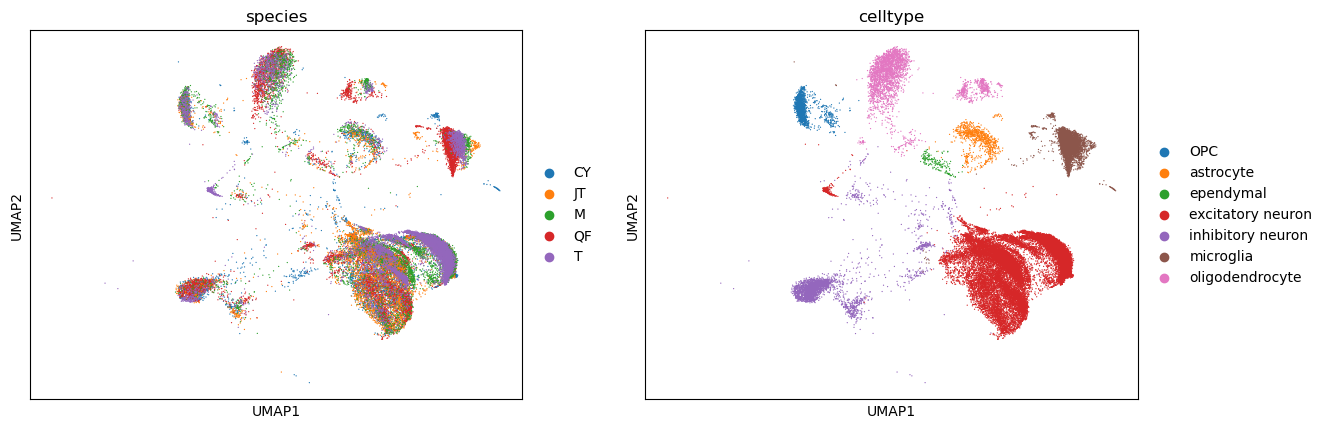

In [2]:
scdata = sc.read_h5ad('hmdata_full.h5ad')
sc.pl.umap(scdata, color = ['species','celltype'])

In [ ]:
sc.pp.highly_variable_genes(scdata, n_top_genes=3000)
scdata = scdata[:, scdata.var.highly_variable]
print(scdata.shape)

sc.tl.pca(scdata)
sc.pl.pca(scdata, color = ['species','celltype'])
sc.pp.neighbors(scdata, n_neighbors=10, n_pcs=30)
sc.tl.umap(scdata)
sc.pl.umap(scdata, color = ['species','celltype'])

In [ ]:
import scanpy.external as sce 

sce.pp.harmony_integrate(scdata, 
                         key = ['species'],
                         max_iter_harmony = 20, 
                         sigma = 0.1, 
                         random_state = 0,
                         theta =2)

sc.pp.neighbors(scdata, use_rep = 'X_pca_harmony')
sc.tl.umap(scdata)
sc.pl.umap(scdata, color = ['species', 'celltype'])


In [6]:
scdata.write_h5ad('hmdata_full_harmony.h5ad')

In [ ]:
scdata